# Socratic tutor study: descriptive results by class group

Real participants only, with exclusions and class groups defined once in `analysis/study_data.py`.
Descriptive only: no significance tests, and no measure of reasoning quality (that needs rubric scoring).

**Before sharing:** clear all outputs. The last cells print students' written answers.

To refresh the data: `python -m scripts.export_study_data`, then set `DATA_DIR` below to the new folder.

In [1]:
import sys
from pathlib import Path
import pandas as pd

# Run from the analysis/ folder (or the repo root); both work.
ROOT = Path.cwd() if (Path.cwd() / "analysis").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from analysis.study_data import load_study, CONDITION_ORDER, EXCLUDED_COHORTS, EXCLUDED_SUBJECTS

DATA_DIR = ROOT / "analysis" / "data"   # folder with the export_*.csv files
pd.set_option("display.max_rows", 200)

study = load_study(DATA_DIR)
if study.unmapped_cohorts:
    print("Cohorts not in COHORT_GROUPS (shown under their own code):", study.unmapped_cohorts)
print("Excluded cohorts:", list(EXCLUDED_COHORTS))
print("Excluded subjects:", len(EXCLUDED_SUBJECTS))

/Users/anissawilliams/Developer/socratic_agentic_ai/analysis/study_data.py:325: UserWarning: Excludes not found in the exports (use study_participation_id): ['67241e34-8530-44cb-8565-f45cfe54513b']
  warnings.warn(f"Excludes not found in the exports (use study_participation_id): {sorted(listed - matched)}")


Excluded cohorts: ['gsu_invoice_overlap']
Excluded subjects: 1


## Who took part

In [2]:
study.completion()

status                                    complete  demographics  posttest  \
group             round_number condition                                     
GSU hotel         1            Control          29             1         0   
                               Socratic         29             1         0   
GSU invoice       1            Control          16             1         1   
                               Socratic         15             3         0   
Spain (policy/IR) 1            Control          12             0         0   
                               Socratic         12             0         0   
                  2            Control          12             0         0   
                               Socratic         12             0         0   

status                                    tutor  total  
group             round_number condition                
GSU hotel         1            Control        0     30  
                               Socratic       0     30  
GSU invoice       1            Control        1     19  
                               Socratic       0     18  
Spain (policy/IR) 1            Control        0     12  
                               Socratic       0     12  
                  2            Control        0     12  
                               Socratic       0     12

In [3]:
study.demographics_summary()

,students,age_median,age_missing,gender_female,gender_male,gender_prefer_not_to_say,level_graduate
group,,,,,,,
GSU hotel,58,27.0,5,35,22,1.0,58
GSU invoice,33,26.0,4,14,19,0.0,33
Spain (policy/IR),24,24.0,3,16,8,0.0,24


## Time on task (minutes, start of round to final submit)

In [4]:
study.time_on_task()

count  mean  median   min    max
group             round_number condition                                  
GSU hotel         1            Control       29  32.5    31.9  28.3   37.7
                               Socratic      29  38.5    32.9  28.3  111.9
GSU invoice       1            Control       16  34.3    33.5  29.0   50.9
                               Socratic      15  33.9    32.5  28.7   58.4
Spain (policy/IR) 1            Control       12  33.2    33.1  30.5   36.1
                               Socratic      12  34.6    34.8  32.1   36.1
                  2            Control       12  24.6    24.1  22.8   27.4
                               Socratic      12  27.0    27.5  24.4   28.5

## AI interaction

In [5]:
study.interaction()

session_min_mean  turns_mean  \
group             round_number condition                                 
GSU hotel         1            Control                15.7         5.7   
                               Socratic               16.1         7.4   
GSU invoice       1            Control                17.0         7.5   
                               Socratic               15.7         7.2   
Spain (policy/IR) 1            Control                16.1         8.6   
                               Socratic               17.3        10.2   
                  2            Control                14.3        10.6   
                               Socratic               16.1        10.1   

                                          student_words_per_turn_med  \
group             round_number condition                               
GSU hotel         1            Control                          13.0   
                               Socratic                         28.5   
GSU invoice       1            Control                          20.5   
                               Socratic                         28.0   
Spain (policy/IR) 1            Control                          17.0   
                               Socratic                         17.0   
                  2            Control                          13.0   
                               Socratic                         21.0   

                                          student_words_total_med  \
group             round_number condition                            
GSU hotel         1            Control                      100.0   
                               Socratic                     214.0   
GSU invoice       1            Control                      154.0   
                               Socratic                     327.0   
Spain (policy/IR) 1            Control                      229.0   
                               Socratic                     250.5   
                  2            Control                      216.0   
                               Socratic                     262.0   

                                          ai_words_per_turn_med  \
group             round_number condition                          
GSU hotel         1            Control                    148.5   
                               Socratic                    29.0   
GSU invoice       1            Control                    131.0   
                               Socratic                    32.0   
Spain (policy/IR) 1            Control                    223.0   
                               Socratic                    34.0   
                  2            Control                    170.0   
                               Socratic                    31.0   

                                          latency_med_s  latency_p90_s  \
group             round_number condition                                 
GSU hotel         1            Control              4.6            8.7   
                               Socratic            19.9           27.1   
GSU invoice       1            Control              3.4            7.4   
                               Socratic            20.3           27.4   
Spain (policy/IR) 1            Control              8.1           13.2   
                               Socratic            28.3           38.3   
                  2            Control              5.8           11.6   
                               Socratic            27.2           36.5   

                                          failed_turns  
group             round_number condition                
GSU hotel         1            Control               0  
                               Socratic              0  
GSU invoice       1            Control               0  
                               Socratic              0  
Spain (policy/IR) 1            Control               0  
                               Socratic              0  
                  2  

In [6]:
study.session_endings()

end_reason_code                           evaluator  participant  timeout
group             round_number condition                                 
GSU hotel         1            Control            0           21        8
                               Socratic          18            3        8
GSU invoice       1            Control            0            8        9
                               Socratic           7            5        3
Spain (policy/IR) 1            Control            0            9        3
                               Socratic           1            4        7
                  2            Control            0           12        0
                               Socratic           4            8        0

## Assessments: timeouts and answer length

In [7]:
study.assessments()

n  timeouts  words_median
group             round_number condition stage                               
GSU hotel         1            Control   pretest   29        12         108.0
                                         posttest  29         6         102.0
                               Socratic  pretest   29        15          96.0
                                         posttest  29        12         104.0
GSU invoice       1            Control   pretest   18         7         207.0
                                         posttest  17         3         181.0
                               Socratic  pretest   15         7          79.0
                                         posttest  15         7         119.0
Spain (policy/IR) 1            Control   pretest   12         4         135.5
                                         posttest  12         7         150.5
                               Socratic  pretest   12         1         125.5
                                         posttest  12         6         142.0
                  2            Control   pretest   12         1         154.5
                                         posttest  12         0         182.5
                               Socratic  pretest   12         4         174.0
                                         posttest  12         3         154.0

In [8]:
study.pre_post_change()

count  mean  median
group             round_number condition                     
GSU hotel         1            Control       29  13.3     6.0
                               Socratic      29  13.3     0.0
GSU invoice       1            Control       17   0.7     6.0
                               Socratic      15  11.7    40.0
Spain (policy/IR) 1            Control       12  33.3    27.5
                               Socratic      12  21.0    25.0
                  2            Control       12  49.8    47.5
                               Socratic      12   4.4    15.5

In [9]:
study.words_by_construct()

condition                                                     Control  \
group             round_number stage    construct_code                  
GSU hotel         1            posttest counterargument          20.0   
                                        evidence_reasoning       29.0   
                                        recommendation           35.0   
                                        uncertainty_revision     19.5   
                               pretest  counterargument          17.5   
                                        evidence_reasoning       34.5   
                                        recommendation           39.5   
                                        uncertainty_revision     18.0   
GSU invoice       1            posttest counterargument          42.0   
                                        evidence_reasoning       61.0   
                                        recommendation           44.0   
                                        uncertainty_revision     52.0   
                               pretest  counterargument          51.0   
                                        evidence_reasoning       60.0   
                                        recommendation           48.5   
                                        uncertainty_revision     63.0   
Spain (policy/IR) 1            posttest counterargument          21.0   
                                        evidence_reasoning       38.0   
                                        recommendation           87.5   
                                        uncertainty_revision     17.5   
                               pretest  counterargument          18.0   
                                        evidence_reasoning       37.0   
                                        recommendation           42.5   
                                        uncertainty_revision     17.5   
                  2            posttest counterargument          33.0   
                                        evidence_reasoning       51.5   
                                        recommendation           50.0   
                                        uncertainty_revision     29.0   
                               pretest  counterargument          20.0   
                                        evidence_reasoning       24.5   
                                        recommendation           49.5   
                                        uncertainty_revision     27.0   

condition                                                     Socratic  
group             round_number stage    construct_code                  
GSU hotel         1            posttest counterargument           23.5  
                                        evidence_reasoning        36.0  
                                        recommendation            31.0  
                                        uncertainty_revision      22.0  
                               pretest  counterargument           23.0  
                                        evidence_reasoning        48.5  
                                        recommendation            35.0  
                                        uncertainty_revision      26.0  
GSU invoice       1            posttest counterargument           40.0  
                                        evidence_reasoning        53.5  
                                        recommendation            40.5  
                                        uncertainty_revision      42.0  
                               pretest  counterargument           49.0  
                                        evidence_reasoning        59.0  
                                        recommendation            30.0  
                                        uncertainty_revision      49.0  
Spain (policy/IR) 1            posttest counterargument           19.0  
                                        evidence_reasoning        29.5  
                                        recommendation   

## Final survey (Round 2 only)

In [10]:
study.survey_means()

group                                   Spain (policy/IR)         
condition                                         Control Socratic
Helped me understand the material                    3.92     3.00
I felt engaged                                       3.92     3.33
Made me think carefully                              4.08     3.83
Encouraged me to explain my reasoning                3.33     4.17
Made me reconsider my thinking                       3.67     4.00
Confident I could explain it to someone              4.00     4.00

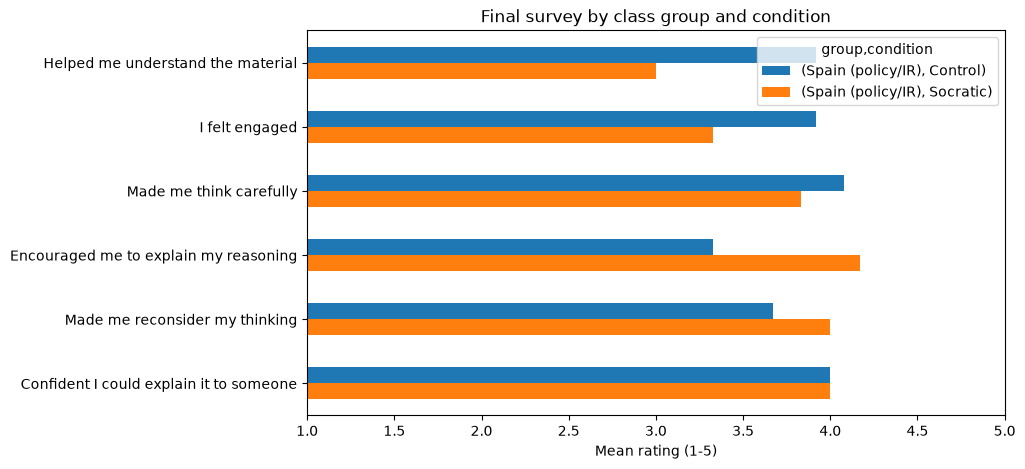

In [11]:
means = study.survey_means()
if not means.empty:
    ax = means.plot.barh(figsize=(9, 5), xlim=(1, 5))
    ax.set_xlabel("Mean rating (1-5)"); ax.invert_yaxis(); ax.set_title("Final survey by class group and condition")

## Evaluator and router (Socratic only)

What the evaluator decided after each student turn, and where the router sent the conversation next.

In [12]:
study.phase_moves()

phase_after_code,aporia,dialectic,elenchus,maieutics
phase_before_code,,,,
aporia,11,29,3,19
dialectic,43,175,22,48
elenchus,13,56,19,25
maieutics,8,59,7,20


In [13]:
study.evaluation_summary()

evaluation_decision_code        advance  stay  phase_goal_met_%
group             round_number                                 
GSU hotel         1                 188    18              91.0
GSU invoice       1                  90    18              81.0
Spain (policy/IR) 1                  67    55              55.0
                  2                  88    33              72.0

In [14]:
ev = study.evaluations()
pd.set_option("display.max_colwidth", 200)
first = ev["study_participation_id"].iloc[0] if not ev.empty else None
ev[ev["study_participation_id"] == first]  # one full conversation; change `first` to read another

,group,round_number,study_participation_id,turn_number,student_message,phase_before_code,phase_goal_satisfied,evaluation_decision_code,evaluation_reasoning_summary,evaluation_evidence,...,follow_up_target,routing_action_code,routing_selected_phase_code,routing_topic_code,routing_move_type_code,routing_target,routing_reasoning_summary,phase_after_code,tutor_response,session_goal_satisfied
577,GSU hotel,1,009e6e53-ab51-48e8-a0f6-5f33f109b9ba,1,"The company should not expand the promotion to all 24 hotels yet. It should first run a short, controlled test at randomly selected hotels, compared with similar hotels that don’t get the promotio...",elenchus,False,stay,"The learner gave a clear recommendation and proposed a stronger test, but did not explicitly explain the main reason the current evidence is insufficient to justify expansion. A focused Elenchus f...","The learner recommends that the company “should not expand…yet” and instead use “randomly selected hotels,” comparison hotels, and measures of “profit as well as bookings,” but does not identify a...",...,"The specific limitation in the current evidence—such as nonrandom hotel selection, seasonal demand, or changes at nonparticipating hotels—that supports delaying expansion and conducting a controll...",stay,elenchus,causal_evidence,examine_evidence,Examine how selecting the eight participating hotels partly for historically strong online booking performance weakens the claim that the promotion caused their booking increase and therefore supp...,"The learner has already proposed a controlled test and a clear recommendation, but has not grounded that recommendation in the scenario’s existing evidence. The nonrandom selection is a specific s...",elenchus,The eight hotels were chosen partly because they already had strong online booking results. How does that choice make the 12% increase less convincing as proof that the promotion caused it?,False
578,GSU hotel,1,009e6e53-ab51-48e8-a0f6-5f33f109b9ba,2,Choosing hotels that already did well online means the test and comparison groups weren’t alike from the start. That makes it hard to tell whether the 12% came from the promotion or from the hotel...,elenchus,True,advance,"The learner directly explained why nonrandom selection weakens the causal claim: the participating and comparison hotels differed at baseline, so the observed increase could reflect hotel characte...",The learner stated that the groups “weren’t alike from the start” and that this makes it difficult to determine whether the 12% increase “came from the promotion or from the hotels themselves.”,...,"Compare the participating hotels’ increase with the increase at the other hotels and assess what that comparison, together with seasonal demand, implies about the promotion’s likely effect.",switch,dialectic,causal_evidence,compare,"Compare the participating hotels’ increase from 200 to 224 with the other hotels’ increase from 180 to 190, then assess what the difference—alongside increased seasonal demand—supports saying abou...",The learner has established selection bias and proposed a stronger future test. The unresolved work is to interpret the contemporaneous comparison: bookings rose in both groups during seasonal dem...,dialectic,"Participating hotels gained 24 weekly bookings, while the others gained 10 during the same seasonal rise. What cautious claim does that 14-booking difference support about the promotion’s added ef...",False
582,GSU hotel,1,009e6e53-ab51-48e8-a0f6-5f33f109b9ba,3,"It supports a modest, provisional claim. During this six-week period, participating hotels gained about 14 more weekly bookings per hotel than non-participating hotels. That is consistent with the...",dialectic,True,advance,The learner directly compared the changes in participating and non-participating hotels and integrated that comparison with a cautious causal interpretation. This satisfies the Dialectic goal even...,The learner stated that participating hotels gained “about

## Tutor supplying numbers (Socratic only)

Turns where the tutor states a number the student has not written yet. A screen for the habit logged in testing; it also flags numbers quoted from the scenario, so read the flagged turns.

In [15]:
flags = study.tutor_supplied_numbers(content_dir=ROOT / "content")
print(len(flags), "flagged turns out of", int((study.turns["condition"] == "Socratic").sum()), "Socratic turns")
flags.groupby(["group", "round_number"]).size() if not flags.empty else flags

58 flagged turns out of 557 Socratic turns


group              round_number
GSU hotel          1               20
GSU invoice        1                1
Spain (policy/IR)  1                6
                   2               31
dtype: int64

In [16]:
pd.set_option("display.max_colwidth", 200)
flags.head(20)

,group,round_number,study_participation_id,turn_number,numbers_introduced,tutor_response
0,GSU hotel,1,009e6e53-ab51-48e8-a0f6-5f33f109b9ba,2,"10, 14","Participating hotels gained 24 weekly bookings, while the others gained 10 during the same seasonal rise. What cautious claim does that 14-booking difference support about the promotion’s added ef..."
1,GSU hotel,1,0880b09b-8427-4de6-be20-90b3f939f8b5,2,14,"Because historically stronger online hotels were chosen, the extra 14-booking increase may reflect more than the promotion. How much of that extra increase can you confidently credit to the promot..."
2,Spain (policy/IR),2,11116e57-256f-4021-85b0-f93e967ef343,1,170000,"Suppose the company adopts Option A, then uses the remaining $170,000 for a small Option B test only if it fits that amount. Given A’s estimated 25%–35% reduction and the uncertainty about contain..."
3,Spain (policy/IR),2,11116e57-256f-4021-85b0-f93e967ef343,2,170000,"What is your full recommendation when comparing Option A, Option B alone, and Option A with a limited Option B test using the remaining $170,000, based on the waste estimates and uncertainties in ..."
4,Spain (policy/IR),2,11116e57-256f-4021-85b0-f93e967ef343,3,170000,"The stated waste benefit for reusable containers depends on at least four uses, while $170,000 may not cover your whole add-on. If you expect fewer than four uses, what evidence would justify incl..."
5,Spain (policy/IR),2,11116e57-256f-4021-85b0-f93e967ef343,4,170000,"A careful recommendation could commit to Option A for the first year while treating Option B only as a small test, without yet claiming its 45%–55% reduction. How would you limit that test so it s..."
6,Spain (policy/IR),2,11116e57-256f-4021-85b0-f93e967ef343,5,170000,"After spending $330,000 on Option A, the company has $170,000 left. What budget rule would ensure the Option B test starts only if its full cost fits that limit while tracking whether containers r..."
7,Spain (policy/IR),2,11116e57-256f-4021-85b0-f93e967ef343,8,170000,"Full Option A leaves at most $170,000 for a B test, while two smaller trials can run only if their estimated total is $500,000 or less. Since reaching four uses must be checked separately, which b..."
8,Spain (policy/IR),2,11116e57-256f-4021-85b0-f93e967ef343,9,170000,"One plan uses about $330,000 for all of Option A, leaving at most $170,000 for an Option B test. The other tests smaller versions of both, but their unknown costs must total no more than $500,000;..."
9,Spain (policy/IR),2,11116e57-256f-4021-85b0-f93e967ef343,10,170000,"Plan 1 fully adopts Option A for about $330,000, then tests Option B only if its complete cost fits within the remaining $170,000. Plan 2 gets the unknown costs for smaller trials of both options,..."


## Written survey answers

In [17]:
pd.set_option("display.max_colwidth", None)
study.survey_text()

,group,condition,open_response,open_response_2
0,Spain (policy/IR),Control,I noticed UI related differences: the table that it tried to present wasn't clear and some of the raw codes were sent rather than texts in the answers,It gave me a framework to work with (only because I asked it explicitly) but it was helpful in developing a reasoning.
1,Spain (policy/IR),Control,Thos chatbot was more straight to the point,"it made me think aboutr the underlying logic of the problem, and it laid out what's at stake on both sides"
2,Spain (policy/IR),Control,"It felt to be reacting a bit more positive about my input. it was also not asking questions in the end that are supposed to make me engage with it again. in that sense, it was trying to close the conversation right away.","its a bit difficult to evaluate that. i am not a fan of AI and i go very negatively into any ai conversation (that i am forced to do) so i already was super biased going into the conversation. in that sense, i was also a bit lost on how ask it for help. i was also very sure that i would not change my opinion based on what it would tell me"
3,Spain (policy/IR),Control,"This form of AI only knows the project and what my inputs which makes it more objective and it does not bring outside information. I also felt as if the machine was not thinking for me, it was just explaining.",It showed me another pathway and highlighted details that I did not take into consideration.
4,Spain (policy/IR),Control,"Yes, it is more contained within the main subject.",It influences my evaluation by encouraging me to go deeper in my explanations.
5,Spain (policy/IR),Control,I did not notice any differences.,"If the AI tool brought some relevant limitations to the problem, I tried to consider these and apply them to the second scenario when evaluating the options or what points would make me reconsider one option."
6,Spain (policy/IR),Control,"Yes, it was more refined and less adapted to my responses. As in, it would not just agree with me instantly. It also added more critical questions than Claude and Gemini usually do.","I considered more variables before reaching a conclusion, although it was the same conclusion, I thought more about my answer."
7,Spain (policy/IR),Control,That it doesn't use outside sources and makes assumptions clear.,"It made me more cautious to not give absolute responses, and also to not make too many assumptions even if sometimes they were logical."
8,Spain (policy/IR),Control,"I think, by nature of the design of the activity, I was much more engaged in an actual discussion with the AI, thinking through options and reasoning, rather than asking a question and simply getting the answer (like so often happens with other AI interactions). I know this is by design - it's the point of the activity, to reason and discuss and expand one's thinking by interacting with it - but it was a difference I definitely observed all the same!","I think it really forced me to think through all possible considerations and helped me to consider factors that I wouldn't have come up with on my own (like providing other scenarios with similar forms of decision-making to help me expand the applicability of the process). I think it's also useful to help me condense my thought process, to focus on the most important factors (like recognizing that with high-risk decisions, where getting it 'wrong' is high-stakes, more caution is wise), and to fully think through different options I may have not considered before."
9,Spain (policy/IR),Control,"I did not notice particular differences, but the fact that I grasped very well the topic and I had little uncertainties render my prompts more precise than usual, receiving a sharper output from the AI tool","It gave me empirical standings for calculations that I only approximated, further strengthening the initial ideas I formed on the case. The specific example was the effective reduction in the percentages of option B once we accounted for the fact 